### Setup

In [ ]:
import sys
import os

!nvcc --version
!which nvcc

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Tue_Feb__7_19:32:13_PST_2023
Cuda compilation tools, release 12.1, V12.1.66
Build cuda_12.1.r12.1/compiler.32415258_0
/usr/local/cuda-12.1/bin/nvcc


In [ ]:
%%capture
!{sys.executable} -m pip install bitsandbytes
!{sys.executable} -m pip install -U -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!{sys.executable} -m pip install -U -q --no-deps "xformers<0.0.26" trl peft accelerate
!{sys.executable} -m pip install flash-attn --no-build-isolation
!{sys.executable} -m spacy download en_core_web_sm
!{sys.executable} -m pip install --pre -U xformers --index-url https://download.pytorch.org/whl/cu121


In [ ]:
!python -c 'import bitsandbytes as bnb; bnb.functional.lib.cdequantize_blockwise_fp32'


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import os
import re
from tqdm import tqdm
import torch
from datasets import Dataset
from trl import SFTTrainer
from transformers import (
                          BitsAndBytesConfig,
                          TrainingArguments,
                          pipeline)
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from unsloth import FastLanguageModel

2024-05-23 15:00:34.575713: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-05-23 15:00:34.607936: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-23 15:00:35.156524: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


### Specifying the path or Downloading the required files

In [ ]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  dir_save = "/content/drive/MyDrive/HLT project"
  dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"
  txt_sent_sent = "/content/drive/MyDrive/HLT project/Project files/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/content/drive/MyDrive/HLT project/Project files/NRC-VAD-Lexicon.txt"

except ModuleNotFoundError:
  dir = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/sentiment_annotated_with_texts.csv"
  dir_save = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project"
  txt_sent_sent = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/NRC-VAD-Lexicon.txt"

### Emptying the memory

In [ ]:
import gc
del model
del trainer
del df
del df2
del df_senti
del train_result

gc.collect()
torch.cuda.empty_cache()


### Loading the dataset and lowering the text

In [ ]:
def norm_text(data):
  return data.lower()

df1 = pd.read_csv(dir, encoding="utf-8", encoding_errors="replace")
df = df1[['true_sentiment','title']]
df = df.sample(frac=1, random_state=44).reset_index(drop=True)
del df1
print(f"Size of data: {len(df)}")
df['title'] = df['title'].map(norm_text)
df[:5]



Size of data: 2291


,true_sentiment,title
0,Negative,usdjpy local factors should support the yen la...
1,Neutral,eurusd now faces some consolidation within 105...
2,Neutral,gbpusd may bounce around in a 120125 range in ...
3,Negative,audusd drops to its lowest level since january...
4,Neutral,audusd whipsaws 20 pips above 06600 on easy au...


### Loading the VAD lexicon

In [ ]:

data = {}

with open(txt_sent_vad, "r") as f:
  t = f.read()
  for si in t.split('\n'):
    si_w = (si +'\t').split('\t')
    if si_w[0] != '' and si_w[0] != 'Word':
      data[si_w[0]] = list(map(lambda fl: float(fl), si_w[1:-1]))
    else:
      pass

for w,v in data.items():
  if len(v) < 3:
    print(w)
df2 = pd.DataFrame(data, index=['valence', 'arousal', 'dominance'])
df2[:5]

,aaaaaaah,aaaah,aardvark,aback,abacus,abalone,abandon,abandoned,abandonment,abashed,...,zit,zodiac,zombie,zone,zoning,zoo,zoological,zoology,zoom,zucchini
valence,0.479,0.520,0.427,0.385,0.510,0.500,0.052,0.046,0.128,0.177,...,0.337,0.594,0.214,0.531,0.417,0.76,0.667,0.568,0.490,0.510
arousal,0.606,0.636,0.490,0.407,0.276,0.480,0.519,0.481,0.430,0.644,...,0.410,0.429,0.648,0.349,0.400,0.52,0.458,0.347,0.520,0.321
dominance,0.291,0.282,0.437,0.288,0.485,0.412,0.245,0.130,0.202,0.307,...,0.381,0.426,0.415,0.382,0.578,0.58,0.492,0.509,0.462,0.250


### Loading the SentiWordNet lexicon

In [ ]:
senti_word = {}
regex = '0(\.\d+)?\s0(\.\d+)?\s([a-z_\-]+#\d+\s)+'
pattern = re.compile(regex)


with open(txt_sent_sent, "r") as f:
  t = f.read()
  for si in t.split("\n"):
    if len(si) > 0 and si[0] != '#':
      matched = pattern.search(si)
      if matched:
        val = matched.group(0).split('\t')
        scor = [float(val[0]), float(val[1])]
        wors = re.split('#\d+\s?', val[2])
        wors.pop(-1)
        for wr in wors:
          senti_word[wr] = scor

df_senti = pd.DataFrame(senti_word, index=["pos_score", "negative_score"])
df_senti[:5]

,able,unable,dorsal,abaxial,ventral,adaxial,acroscopic,basiscopic,abducting,abducent,...,take_fire,conflagrate,catch_fire,flame_up,blaze_up,luminesce,shade_off,cloud_up,run_dry,fog_up
pos_score,0.25,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.000
negative_score,0.00,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0,0.125


### Spliting the dataset

In [ ]:
X_train1 = list()
X_test1 = list()
X_eval = list()
test_perc = 0.20
train_perc = (1.0 - test_perc)



sentiments = ["Positive", "Neutral", "Negative"]



for sent in sentiments:
  train, test = train_test_split(
      df[df['true_sentiment'] == sent],
      train_size=1.0 - test_perc,
      test_size=test_perc,
      random_state=32,
  )
  X_train1.append(train)
  X_test1.append(test)

X_train1 = pd.concat(X_train1).sample(frac=1, random_state=56)
X_test1 = pd.concat(X_test1).sample(frac=1, random_state=42)

#X_train1, X_eval1 = train_test_split(X_train1, train_size=0.9, test_size=0.1)

X_train1 = X_train1.sample(frac=1).reset_index(drop=True)
#X_eval1 = X_eval1.sample(frac=1).reset_index(drop=True)

X_train1[:5]

,true_sentiment,title
0,Negative,audusd fluctuates around 06877 though ended th...
1,Negative,gbpusd hags near ytd low remains vulnerable be...
2,Neutral,usdjpy faces extra consolidation near term – uob
3,Neutral,usdjpy waffles above and below the 200 hour ma
4,Neutral,forex today mixed week for the usd is it time ...


### Prompt generating
It generates the prompt for the train, eval set (with label) and for the test

In [ ]:


def get_sentiment_vad(text):
  text_split = text.split(" ")
  total_score = [0, 0, 0]
  added = 1
  for word in text_split:
    if word in df2:
      total_score[0] += df2[word]['valence']
      total_score[1] += df2[word]['arousal']
      total_score[2] += df2[word]['dominance']
      added += 1
  return np.array(total_score) / added

def get_sentiment(text):
  text_split = text.split(" ")
  total_score = [0, 0]
  added = 1
  for i,word in enumerate(text_split):
    if word in df_senti:
      added += 1
      total_score[0] += df_senti[word]['pos_score']
      total_score[1] += df_senti[word]['negative_score']
    if i > 1:
      if text_split[i-1] + "_" + word in df_senti:
        total_score[0] += df_senti[text_split[i-1] + "_"+word]["pos_score"]
        total_score[1] += df_senti[text_split[i-1] + "_"+word]["negative_score"]
        added += 1

  return np.array(total_score) / added #normalizing for all words; take word, is in lexicon? give score and update (+1)


text="""You are a  sentiment analysis model, perform the sentiment analysis of the headline enclosed in the angle brackets.
These scores related to the  headline  enclosed in the angle brackets must be considered: valence score {:.5f}, arousal score {:.5f}, dominance score {:.5f}, positive SentiWordNet score {:.5f} and negative SentiWordNet score {:.5f}.
It is imperative to keep in mind the direct correlation between the words.
Headline: <{}>

The response must be
\n or 'Positive'
\n or 'Negative'
\n or 'Neutral'
\n\nSolution: the correct option is""".strip()


def formatting_prompts_func(examples):
    all_words = set()
    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format( score_vad[0], score_vad[1], score_vad[2], score[0], score[1],  examples['title']) + " " +  f"'{examples['true_sentiment']}'"




def formatting_prompts_func_test(examples):

    all_words = set()


    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format( score_vad[0], score_vad[1], score_vad[2], score[0], score[1],  examples['title'])



torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

X_train = pd.DataFrame(X_train1.apply(formatting_prompts_func, axis=1), columns=['title'])
#X_eval = pd.DataFrame(X_eval1.apply(formatting_prompts_func, axis=1), columns=['title'])
y_true = X_test1.true_sentiment
X_test = pd.DataFrame(X_test1.apply(formatting_prompts_func_test, axis=1), columns=['title'])

train_data = Dataset.from_pandas(X_train)
#eval_data = Dataset.from_pandas(X_eval)
len(train_data)


1832

In [ ]:
X_train[:1]['title'].to_numpy()

array(["You are a  sentiment analysis model, perform the sentiment analysis of the headline enclosed in the angle brackets.\nThese scores related to the  headline  enclosed in the angle brackets must be considered: valence score 0.27067, arousal score 0.24367, dominance score 0.28367, positive SentiWordNet score 0.06250 and negative SentiWordNet score 0.00000.\nIt is imperative to keep in mind the direct correlation between the words.\nHeadline: <audusd fluctuates around 06877 though ended the week with losses>\n\nThe response must be\n\n or 'Positive'\n\n or 'Negative'\n\n or 'Neutral'\n\n\nSolution: the correct option is 'Negative'"],
      dtype=object)

### The evaluation function

In [ ]:
def evaluate(y_true, y_pred):
  labels = [sent.lower() for sent in sentiments]
  mapping = {sentiments[0]: 2, sentiments[1]: 1, "Unclear": 1, sentiments[2]: 0}
  labels_map = {2: sentiments[0], 1: sentiments[1], 0: sentiments[2]}

  def map_func(x):
    return mapping.get(x, 1)

  y_true = np.vectorize(map_func)(y_true)
  y_pred = np.vectorize(map_func)(y_pred)

  accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
  print(f"Accuracy: {accuracy:.3f}")

  unique_labels = set(y_true)

  for label in unique_labels:
    label_indeces = [i for i in range(len(y_true))
                      if y_true[i] == label]
    label_y_true = [y_true[i] for i in label_indeces]
    label_y_pred = [y_pred[i] for i in label_indeces]
    accuracy = accuracy_score(label_y_true, label_y_pred)
    print(f"Accuracy for label {labels_map[label]}: {accuracy:.3f}")

  class_report = classification_report(y_true=y_true, y_pred=y_pred)
  print("\nClassification Report:")
  print(class_report)

  conf_matrix = confusion_matrix(y_true=y_true, y_pred=y_pred, labels=[0,1,2])
  print("\nConfusion Matrix:")
  disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=sentiments)
  disp.plot()


### Loading the model and the tokenizer

In [ ]:


if os.path.exists(f"{os.getcwd()}/Phi-3-mini-4k-instruct"):
    model_name = f"{os.getcwd()}/Phi-3-mini-4k-instruct/"
else:
    model_name = "unsloth/Phi-3-mini-4k-instruct"




compute_dtype = getattr(torch, "float16")


torch.random.manual_seed(42)
max_seq_length = 2048
dtype = None
load_in_4bit = True

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = model_name,
    use_cache=False,
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    trust_remote_code=True,
    device_map = "auto",
    attn_implementation="flash_attention_2"
)



tokenizer.model_max_length = max_seq_length
tokenizer.pad_token = tokenizer.unk_token  # use unk rather than eos token to prevent endless generation
tokenizer.pad_token_id = tokenizer.convert_tokens_to_ids(tokenizer.pad_token)
tokenizer.padding_side = 'right'
tokenizer.truncation_side = "left"


Unsloth: You passed in `unsloth/Phi-3-mini-4k-instruct` and `load_in_4bit = True`.
We shall load `unsloth/Phi-3-mini-4k-instruct-bnb-4bit` for 4x faster loading.


==((====))==  Unsloth: Fast Mistral patching release 2024.5
   \\   /|    GPU: NVIDIA GeForce RTX 4080 Laptop GPU. Max memory: 11.721 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0+cu121. CUDA = 8.9. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. Xformers = 0.0.26.post1. FA = True.
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


### The predict function for the label

In [ ]:
def predict(X_test, model, tokenizer):
  sent_reg = ".?([P,p]ositive|[N,n]egative|[N,n]eutral)"

  y_pred = []
  for i in tqdm(range(len(X_test))):
    prompt = X_test.iloc[i]['title']
    pipe = pipeline(task="text-generation",
                    model=model,
                    tokenizer=tokenizer,
                    max_new_tokens=6,
                    temperature=0.0,
                    truncation=True)
    result = pipe(prompt, pad_token_id=pipe.tokenizer.eos_token_id, return_full_text=False, do_sample=False)
    answer_match = re.findall(sent_reg, result[0]['generated_text'])
    if len(answer_match) == 1:
      answer = answer_match[0].lower()
      if "positive" in answer:
        y_pred.append("Positive")
      elif "negative" in answer:
        y_pred.append("Negative")
      elif "neutral" in answer:
        y_pred.append("Neutral")
      else:
        print(f"Weird match: {answer}")
        y_pred.append("Unclear")
    else:
      print(f"Not found: {result[0]}")
      y_pred.append("Unclear")
  return y_pred

### Calling the function to test zero-shot prompting

In [ ]:
y_pred = predict(X_test, model, tokenizer)



100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [01:00<00:00,  7.54it/s]


### Evaluation the results

Accuracy: 0.645
Accuracy for label Positive: 0.789
Accuracy for label Neutral: 0.669
Accuracy for label Neutral: 0.487

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.79      0.72       142
           1       0.55      0.67      0.60       163
           2       0.80      0.49      0.60       154

    accuracy                           0.64       459
   macro avg       0.67      0.65      0.64       459
weighted avg       0.67      0.64      0.64       459


Confusion Matrix:


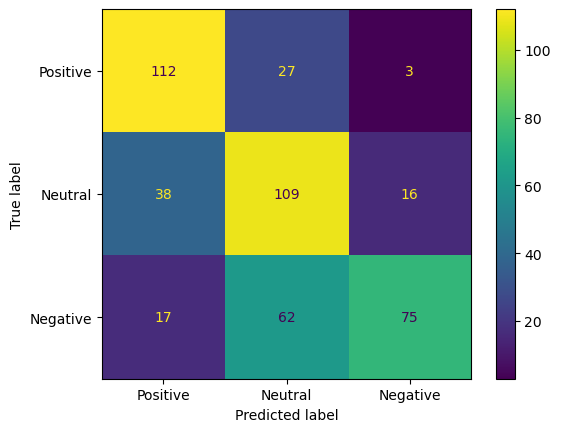

In [ ]:
evaluate(y_true, y_pred)


### Setup for fine-tuning

In [ ]:
model = FastLanguageModel.get_peft_model( #freezes training weights: cross-entropy and force teacher training
    model,
    r = 64, # Choose any number > 0 ! Suggested 8, 16, 32, 64, 128
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 64,
       = 0.05, # Supports any, but = 0 is optimized
    bias = "none",    # Supports any, but = "none" is optimized
    # [NEW] "unsloth" uses 30% less VRAM, fits 2x larger batch sizes!
    use_gradient_checkpointing = True, # True or "unsloth" for very long context
    random_state = 42,
    use_rslora = True,  # We support rank stabilized LoRA
    loftq_config = None, # And LoftQ
)

model.print_trainable_parameters()

Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2024.5 patched 32 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


trainable params: 119,537,664 || all params: 3,940,617,216 || trainable%: 3.0335


### Specifying all fine-tuning settings

In [ ]:
training_config = {
    "do_eval": False,
    "do_train": True,
    "learning_rate": 3.0e-4,
    "adam_epsilon": 2.0e-7,
    "log_level": "info",
    "logging_steps": 10,
    "logging_strategy": "steps",
    "lr_scheduler_type": "polynomial",
    "num_train_epochs": 1,
    "max_steps": -1,
    "output_dir": "./checkpoint_dir",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 8,
    "save_steps": 200,
    "save_total_limit": 1,
    "gradient_checkpointing": True,
    "gradient_checkpointing_kwargs":{"use_reentrant": False},
    "warmup_ratio": 0.25,
    "fp16": not torch.cuda.is_bf16_supported(),
    "bf16": torch.cuda.is_bf16_supported(),
    "optim": "adamw_bnb_8bit",
    "seed": 42,
    "group_by_length":True,
    "weight_decay": 0.01,
    }

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_data,
    dataset_text_field = "title",
    max_seq_length = max_seq_length,
    dataset_num_proc = 4,
    packing = False,
    args = TrainingArguments(
      **training_config
    ),
)
model.print_trainable_parameters()


Map (num_proc=4): 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1832/1832 [00:00<00:00, 3351.14 examples/s]
Using auto half precision backend


trainable params: 119,537,664 || all params: 3,940,617,216 || trainable%: 3.0335


### Run training

In [ ]:
train_result = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 1,832 | Num Epochs = 1
O^O/ \_/ \    Batch size per device = 2 | Gradient Accumulation steps = 8
\        /    Total batch size = 16 | Total steps = 114
 "-____-"     Number of trainable parameters = 119,537,664


Step,Training Loss
10,2.109800
20,0.503500
30,0.441100
40,0.513800
50,0.416800
60,0.437100
70,0.440700
80,0.376300
90,0.409800
100,0.406600




Training completed. Do not forget to share your model on huggingface.co/models =)




### Printing metrics

In [ ]:
metrics = train_result.metrics
trainer.log_metrics("train", metrics)
trainer.save_metrics("train", metrics)
trainer.save_state()

***** train metrics *****
  epoch                    =     0.9956
  total_flos               =  7776123GF
  train_loss               =     0.5744
  train_runtime            = 0:04:47.00
  train_samples_per_second =      6.383
  train_steps_per_second   =      0.397


### Run prediction on fine-tuned model

In [ ]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [01:11<00:00,  6.38it/s]


### Evaluating the final results

Accuracy: 0.817
Accuracy for label Positive: 0.817
Accuracy for label Neutral: 0.761
Accuracy for label Neutral: 0.877

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85       142
           1       0.76      0.76      0.76       163
           2       0.82      0.88      0.85       154

    accuracy                           0.82       459
   macro avg       0.82      0.82      0.82       459
weighted avg       0.82      0.82      0.82       459


Confusion Matrix:


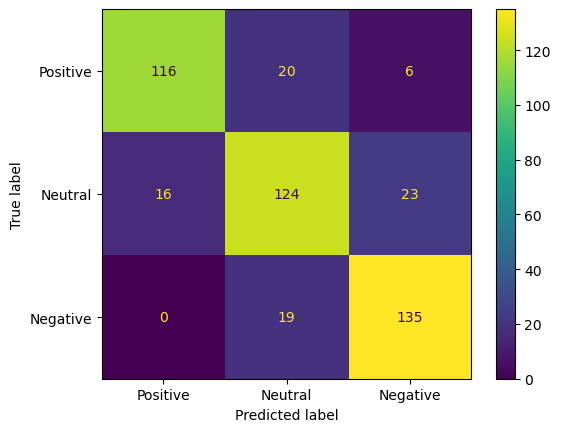

In [ ]:
evaluate(y_true, y_pred)

In [ ]:
model.save_pretrained_merged(f"{dir_save}/fine-tuned-Phi-3-mini-4k-instruct", tokenizer)
